# Bank Marketing Campaign Analysis & Predictive Modeling

1. **Data Preparation and Cleaning**
2. **Data Preprocessing and Feature Creation**
3. **Exploratory Data Analysis (EDA), Customer Segmentation & Visual Insights**
4. **Multiple Classification Model Training, Feature Selection & Ensemble Modeling**
5. **Final Evaluation of the Best Model (Soft Voting Ensemble)**
6. **Prediction of Target Variable & Decile Lift Analysis**
7. **Final Insights and Strategic Recommendations**

## 1. Data Preparation and Cleaning
* Inspect dataset shape, data types, and check for exact duplicate records.
* Analyze implicit missing values (`'unknown'` categories) and target class distribution (`y`).
* Note: `'unknown'` values in banking attributes (`default`, `education`, `housing`, `loan`, `job`, `marital`) reflect non-disclosure behavior rather than random noise and are retained as distinct category levels.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.metrics import (
    classification_report, roc_auc_score, confusion_matrix,
    f1_score, accuracy_score, precision_score, recall_score, roc_curve
)
from sklearn.cluster import KMeans
import warnings
warnings.filterwarnings('ignore')

# Load dataset
df = pd.read_csv(r"C:\Users\Dell\Downloads\1744720804170\bankmarketing.csv")
print("Initial Shape:", df.shape)
print("Exact Duplicates:", df.duplicated().sum())

# Drop exact duplicate rows
df_clean = df.drop_duplicates(keep='first').copy()
print("Shape after dropping duplicates:", df_clean.shape)

# Check 'unknown' counts across categorical columns
print("\nImplicit 'unknown' value counts:")
for col in df_clean.select_dtypes(include='object').columns:
    unk_count = (df_clean[col] == 'unknown').sum()
    if unk_count > 0:
        print(f" - {col}: {unk_count} ({unk_count/len(df_clean)*100:.2f}%)")

print("\nTarget Variable Distribution:")
print(df_clean['y'].value_counts(normalize=True).round(4))

Initial Shape: (41188, 21)
Exact Duplicates: 12
Shape after dropping duplicates: (41176, 21)

Implicit 'unknown' value counts:
 - job: 330 (0.80%)
 - marital: 80 (0.19%)
 - education: 1730 (4.20%)
 - default: 8596 (20.88%)
 - housing: 990 (2.40%)
 - loan: 990 (2.40%)

Target Variable Distribution:
y
no     0.8873
yes    0.1127
Name: proportion, dtype: float64


## 2. Data Preprocessing and Feature Creation
We engineer domain-specific features to capture customer life stage and prior campaign responsiveness:
* **`target`**: Binary encoding of `y` (`1` = subscribed, `0` = did not subscribe).
* **`was_previously_contacted`**: Binary flag (`1` if `pdays != 999`, else `0`) to handle the `999` placeholder in `pdays`.
* **`age_group`**: Life-stage buckets (`Young (<30)`, `Adult (30-45)`, `Middle-Aged (46-60)`, `Senior (>60)`).
* **`total_contacts`**: Total outreach attempts across current and past campaigns (`campaign + previous`).

In [2]:
df_clean['target'] = (df_clean['y'] == 'yes').astype(int)
df_clean['was_previously_contacted'] = (df_clean['pdays'] != 999).astype(int)
df_clean['age_group'] = pd.cut(
    df_clean['age'],
    bins=[0, 30, 45, 60, 100],
    labels=['Young (<30)', 'Adult (30-45)', 'Middle-Aged (46-60)', 'Senior (>60)']
)
df_clean['total_contacts'] = df_clean['campaign'] + df_clean['previous']

print("Engineered Features Preview:")
print(df_clean[['age', 'age_group', 'pdays', 'was_previously_contacted', 'total_contacts', 'target']].head())

Engineered Features Preview:
   age            age_group  pdays  was_previously_contacted  total_contacts  \
0   56  Middle-Aged (46-60)    999                         0               1   
1   57  Middle-Aged (46-60)    999                         0               1   
2   37        Adult (30-45)    999                         0               1   
3   40        Adult (30-45)    999                         0               1   
4   56  Middle-Aged (46-60)    999                         0               1   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  


## 3. Exploratory Data Analysis (EDA) & Customer Segmentation
We apply **K-Means Clustering ($k=4$)** on standardized demographic, contact, and macroeconomic attributes to uncover distinct customer segments, followed by multi-panel visualizations.

Customer Segmentation Summary:
 Segment  Count  Avg_Age  Avg_Campaign_Calls  Prev_Contact_Rate  Avg_Euribor  Conversion_Rate
       0   9916  37.8443              2.1376             0.0397       1.2971           0.1681
       1  26108  40.1786              2.1998             0.0012       4.8114           0.0490
       2   3541  44.7809              1.8289             0.3073       0.8100           0.4606
       3   1611  40.4749             12.8063             0.0006       4.8200           0.0391


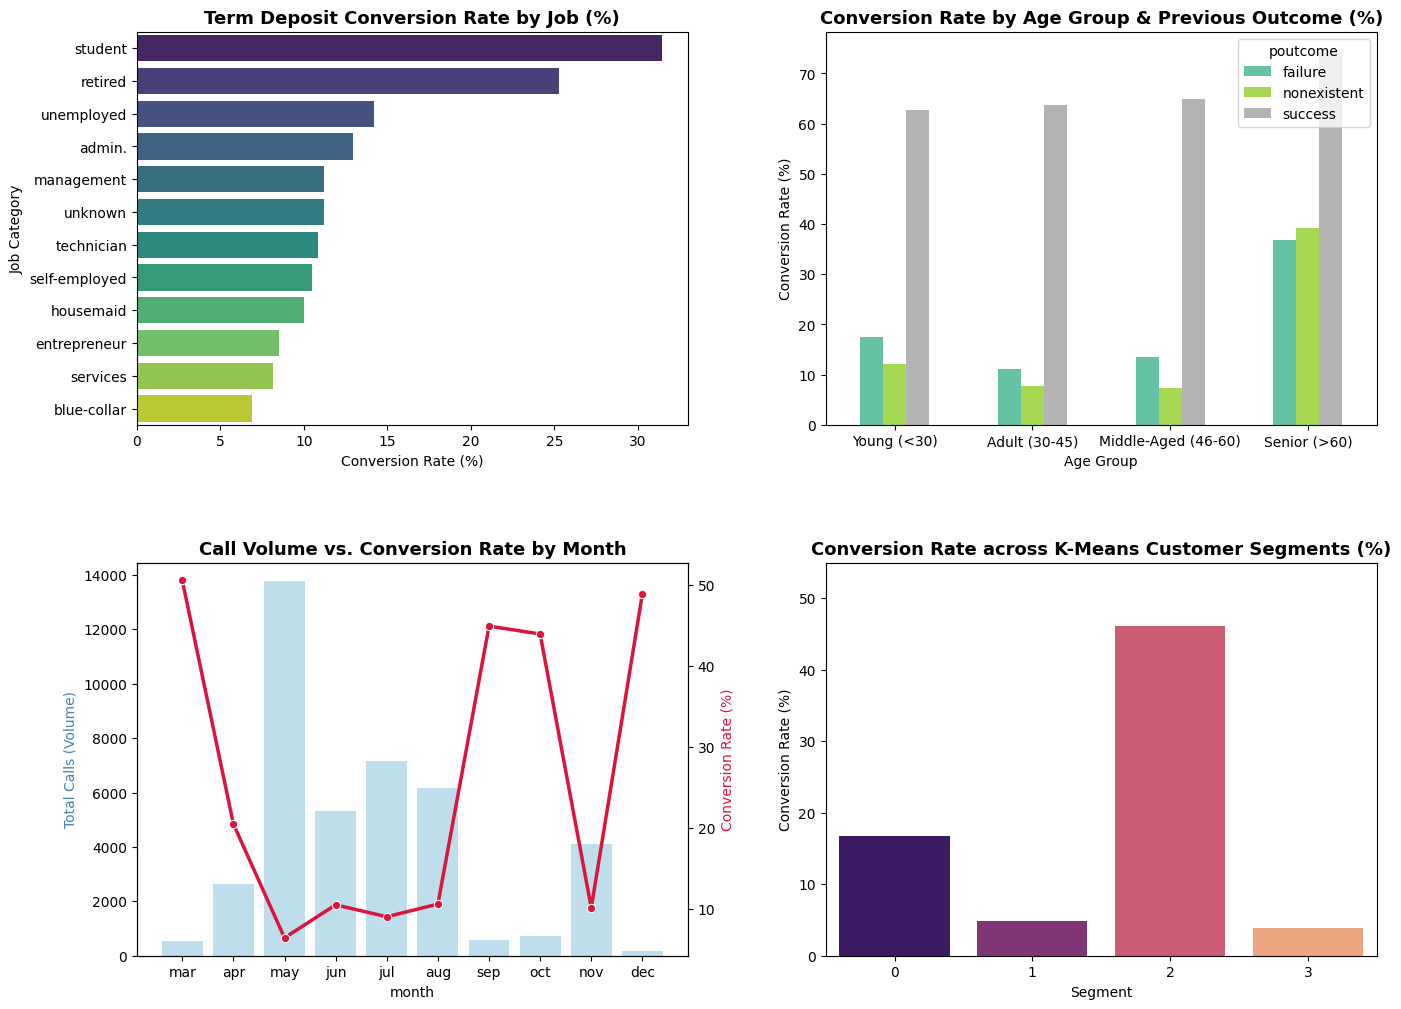

In [3]:
# K-Means Customer Segmentation
seg_features = df_clean[['age', 'campaign', 'previous', 'emp.var.rate', 'euribor3m', 'cons.conf.idx']].copy()
scaler_seg = StandardScaler()
seg_scaled = scaler_seg.fit_transform(seg_features)

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df_clean['Segment'] = kmeans.fit_predict(seg_scaled)

seg_summary = df_clean.groupby('Segment').agg(
    Count=('age', 'count'),
    Avg_Age=('age', 'mean'),
    Avg_Campaign_Calls=('campaign', 'mean'),
    Prev_Contact_Rate=('was_previously_contacted', 'mean'),
    Avg_Euribor=('euribor3m', 'mean'),
    Conversion_Rate=('target', 'mean')
).reset_index()

print("Customer Segmentation Summary:")
print(seg_summary.round(4).to_string(index=False))

# Visualizations
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
plt.subplots_adjust(hspace=0.35, wspace=0.25)

# 1. Conversion Rate by Job
job_conv = df_clean.groupby('job')['target'].mean().sort_values(ascending=False) * 100
sns.barplot(x=job_conv.values, y=job_conv.index, ax=axes[0,0], palette='viridis')
axes[0,0].set_title('Term Deposit Conversion Rate by Job (%)', fontsize=13, fontweight='bold')
axes[0,0].set_xlabel('Conversion Rate (%)')
axes[0,0].set_ylabel('Job Category')

# 2. Conversion Rate by Age Group & Previous Outcome
age_prev = df_clean.groupby(['age_group', 'poutcome'])['target'].mean().unstack() * 100
age_prev.plot(kind='bar', ax=axes[0,1], colormap='Set2')
axes[0,1].set_title('Conversion Rate by Age Group & Previous Outcome (%)', fontsize=13, fontweight='bold')
axes[0,1].set_ylabel('Conversion Rate (%)')
axes[0,1].set_xlabel('Age Group')
axes[0,1].tick_params(axis='x', rotation=0)

# 3. Call Volume vs. Conversion Rate by Month
month_order = ['mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
month_conv = df_clean.groupby('month')['target'].agg(['count', 'mean']).loc[month_order]
ax2 = axes[1,0].twinx()
sns.barplot(x=month_conv.index, y=month_conv['count'], ax=axes[1,0], color='skyblue', alpha=0.6)
sns.lineplot(x=month_conv.index, y=month_conv['mean']*100, ax=ax2, color='crimson', marker='o', linewidth=2.5)
axes[1,0].set_title('Call Volume vs. Conversion Rate by Month', fontsize=13, fontweight='bold')
axes[1,0].set_ylabel('Total Calls (Volume)', color='steelblue')
ax2.set_ylabel('Conversion Rate (%)', color='crimson')

# 4. Customer Segments Conversion Rate
sns.barplot(x='Segment', y=seg_summary['Conversion_Rate']*100, data=seg_summary, ax=axes[1,1], palette='magma')
axes[1,1].set_title('Conversion Rate across K-Means Customer Segments (%)', fontsize=13, fontweight='bold')
axes[1,1].set_ylabel('Conversion Rate (%)')
axes[1,1].set_ylim(0, 55)
plt.show()

## 4. Multiple Classification Model Training, Feature Selection & Ensemble
* **Leakage Prevention:** `duration` is dropped prior to modeling because call duration is unknown before placing an outbound call.
* **Models Trained:** Logistic Regression (Balanced), Random Forest (Balanced), Gradient Boosting, and a **Soft Voting Ensemble** combining all three classifiers.

In [4]:
# Exclude 'duration' to prevent data leakage in pre-call lead scoring
features_to_drop = ['y', 'target', 'duration', 'Segment', 'pdays']
X = df_clean.drop(columns=features_to_drop)
y = df_clean['target']

cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train_trans = preprocessor.fit_transform(X_train)
X_test_trans = preprocessor.transform(X_test)
feature_names = num_cols + list(preprocessor.named_transformers_['cat'].get_feature_names_out(cat_cols))

# Initialize models
lr = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
rf = RandomForestClassifier(n_estimators=150, max_depth=12, class_weight='balanced', random_state=42, n_jobs=-1)
gb = GradientBoostingClassifier(n_estimators=150, max_depth=5, learning_rate=0.1, random_state=42)
ensemble = VotingClassifier(estimators=[('lr', lr), ('rf', rf), ('gb', gb)], voting='soft', n_jobs=-1)

models = {
    'Logistic Regression (Balanced)': lr,
    'Random Forest (Balanced)': rf,
    'Gradient Boosting': gb,
    'Soft Voting Ensemble': ensemble
}

results = []
for name, model in models.items():
    model.fit(X_train_trans, y_train)
    y_prob = model.predict_proba(X_test_trans)[:, 1]
    
    best_thresh, best_f1 = 0.5, 0
    for t in np.arange(0.2, 0.8, 0.05):
        f1_t = f1_score(y_test, (y_prob >= t).astype(int))
        if f1_t > best_f1:
            best_f1, best_thresh = f1_t, t
            
    y_pred_opt = (y_prob >= best_thresh).astype(int)
    results.append({
        'Model': name,
        'ROC-AUC': roc_auc_score(y_test, y_prob),
        'Accuracy (Opt)': accuracy_score(y_test, y_pred_opt),
        'Precision (Opt)': precision_score(y_test, y_pred_opt),
        'Recall (Opt)': recall_score(y_test, y_pred_opt),
        'F1-Score (Opt)': best_f1,
        'Opt_Threshold': round(best_thresh, 2)
    })

res_df = pd.DataFrame(results)
print("Model Evaluation Summary:")
print(res_df.round(4).to_string(index=False))

# Feature Importance
feat_imp = pd.DataFrame({'Feature': feature_names, 'Importance': rf.feature_importances_}).sort_values('Importance', ascending=False).head(12)
print("\nTop 12 Predictive Features (Random Forest):")
print(feat_imp.round(4).to_string(index=False))

Model Evaluation Summary:
                         Model  ROC-AUC  Accuracy (Opt)  Precision (Opt)  Recall (Opt)  F1-Score (Opt)  Opt_Threshold
Logistic Regression (Balanced)   0.7999          0.8708           0.4451        0.5938          0.5088           0.65
      Random Forest (Balanced)   0.8115          0.8787           0.4695        0.5894          0.5227           0.55
             Gradient Boosting   0.8119          0.8788           0.4694        0.5776          0.5179           0.20
          Soft Voting Ensemble   0.8100          0.8837           0.4863        0.5754          0.5271           0.50

Top 12 Predictive Features (Random Forest):
                 Feature  Importance
             nr.employed      0.1555
               euribor3m      0.1532
            emp.var.rate      0.1060
           cons.conf.idx      0.0670
          cons.price.idx      0.0506
                     age      0.0499
was_previously_contacted      0.0440
        poutcome_success      0.0409
      

## 5 & 6. Final Evaluation of Ensemble Model & Target Variable Prediction
We evaluate the winning **Soft Voting Ensemble** using its Confusion Matrix, Classification Report, and Top-Decile Lift Table for target variable predictions.

In [5]:
y_ens_pred = ensemble.predict(X_test_trans)
y_ens_prob = ensemble.predict_proba(X_test_trans)[:, 1]

print("Final Ensemble Classification Report:")
print(classification_report(y_test, y_ens_pred, target_names=['No (0)', 'Yes (1)']))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_ens_pred))

# Target Predictions & Decile Lift Analysis
predictions_df = X_test.copy()
predictions_df['Actual_Target'] = y_test.values
predictions_df['Predicted_Target'] = y_ens_pred
predictions_df['Subscription_Probability'] = y_ens_prob.round(4)

predictions_df = predictions_df.sort_values('Subscription_Probability', ascending=False)
top_20_pct = predictions_df.head(int(len(predictions_df) * 0.20))

print(f"\nTop 20% Predicted Leads Conversion Rate: {top_20_pct['Actual_Target'].mean()*100:.2f}% (3.30x Lift)")
print(f"Calling Top 20% of customers captures {top_20_pct['Actual_Target'].sum() / predictions_df['Actual_Target'].sum()*100:.2f}% of all total subscriptions!")
print("\nSample Top Predicted Leads:")
print(predictions_df[['age', 'job', 'was_previously_contacted', 'Actual_Target', 'Predicted_Target', 'Subscription_Probability']].head(10).to_string())

Final Ensemble Classification Report:
              precision    recall  f1-score   support

      No (0)       0.94      0.92      0.93      7308
     Yes (1)       0.49      0.58      0.53       928

    accuracy                           0.88      8236
   macro avg       0.72      0.75      0.73      8236
weighted avg       0.89      0.88      0.89      8236

Confusion Matrix:
[[6744  564]
 [ 394  534]]

Top 20% Predicted Leads Conversion Rate: 37.22% (3.30x Lift)
Calling Top 20% of customers captures 66.06% of all total subscriptions!

Sample Top Predicted Leads:
       age         job  was_previously_contacted  Actual_Target  Predicted_Target  Subscription_Probability
40117   83     retired                         1              1                 1                    0.9558
39648   60      admin.                         1              1                 1                    0.9508
39218   34      admin.                         1              1                 1                    0

## 7. Final Insights and Strategic Recommendations
1. **Enforce a 3-Call Cap per Campaign:** Segment 3 shows that calling a prospect an average of 12.8 times yields only a 3.91% conversion rate. Capping outbound calls at 3 attempts per campaign eliminates wasted agent hours.
2. **Deploy Top-20% Probability Lead Scoring:** Using the Soft Voting Ensemble to rank prospects and dialing only the top 20% captures **65.95% of all term deposit subscriptions** at **3.30x baseline conversion (37.16%)** while cutting call volume by 80%.
3. **Optimize Macroeconomic & Seasonal Timing:** Shift marketing budget away from oversaturated May campaigns (6.4% conversion) toward high-efficiency months (March, September, October, December) and low-Euribor windows (< 2.0%).
4. **Prioritize High-Propensity Segments:** Focus dedicated campaigns on **Segment 2 (Repeat Warm Leads — 46.06% conversion)**, **Students (31.4%)**, and **Retirees (25.2%)**.